In [ ]:
# ===== Standard library =====
import csv
import datetime
import glob
import os
import random
import re
from collections import Counter
from datetime import timedelta

# ===== Numerical & data handling =====
import numpy as np
import pandas as pd
import polars as pl
from joblib import load
from numpy.random import default_rng

# ===== Visualization =====
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# ===== Scikit-learn =====
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    average_precision_score,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    KFold,
    train_test_split,
)
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    StandardScaler,
)
from sklearn.utils.class_weight import compute_class_weight

# ===== Imbalanced-learn =====
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# ===== TensorFlow / Keras =====
import tensorflow as tf
from keras.utils import to_categorical
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
)
from tensorflow.keras.layers import (
    Activation,
    Add,
    BatchNormalization,
    Concatenate,
    Conv1D,
    Dense,
    Dropout,
    Embedding,
    Flatten,
    GlobalAveragePooling1D,
    Input,
    MaxPooling1D,
)
from tensorflow.keras.models import Model, Sequential

# ===== Project-specific modules =====
import utils.data_models as data_models
import utils.data_preprocessing as data_preprocessing
from utils.data_integration import combine_data, read_data

In [16]:
# convert all sublists to arrays
def flatten(subject):
    array_data = [np.array(x) for x in subject]  
    flattened_data = np.concatenate(array_data, axis=0)
    return flattened_data

## TCN

In [ ]:
from joblib import load
X_test, Y_test = load("Data/DL_Test.joblib")

In [ ]:
from joblib import load
X_train, Y_train = load("Data/DL_TrainL.joblib")

In [ ]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)


# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)
# split into temp and test (20%)
abl_train_idx, abl_val_idx = train_test_split(abl_idx, test_size=0.20, shuffle=True, random_state=seed_value)


X_train_fold = [X_train[i] for i in train_idx]
Y_train_fold = [Y_train[i] for i in train_idx]

X_abl_train_fold = [X_train[i] for i in abl_train_idx]
Y_abl_train_fold = [Y_train[i] for i in abl_train_idx]

X_abl_val_fold = [X_train[i] for i in abl_val_idx]
Y_abl_val_fold = [Y_train[i] for i in abl_val_idx]

print(len(train_idx))
print(len(abl_train_idx))
print(len(abl_val_idx))
print(len(X_test))

# flattens the arrays of single subjects into one array of shape (X,25,2)
Y_train_fold  =flatten(Y_train_fold)
Y_train_fold= Y_train_fold.reshape(-1)

Y_abl_train_fold =flatten(Y_abl_train_fold)
Y_abl_train_fold= Y_abl_train_fold.reshape(-1)

Y_abl_val_fold =flatten(Y_abl_val_fold)
Y_abl_val_fold= Y_abl_val_fold.reshape(-1)

Y_test_fold =flatten(Y_test)
Y_test_fold= Y_test_fold.reshape(-1)



# flattens the arrays of single subjects into one array of shape (X,1)
X_train_fold = flatten(X_train_fold)
X_abl_train_fold = flatten(X_abl_train_fold)
X_abl_val_fold = flatten(X_abl_val_fold)
X_test_fold = flatten(X_test)


print(X_train_fold.shape)
print(X_abl_train_fold.shape)
print(X_abl_val_fold.shape)
print(X_test_fold.shape)

# initiliazes buffer size and batch size 
"""BUFFER_SIZE = len(X_train_fold) 
BATCH_SIZE = 64"""

BATCH_SIZE =  256 #1024 #512 #2048 #256
BUFFER_SIZE = min(len(X_train_fold), 10_000)
SEED = 42

Y_train_rs = to_categorical(Y_train_fold)
Y_test_rs = to_categorical(Y_test_fold)
Y_abl_train_rs = to_categorical(Y_abl_train_fold)
Y_abl_val_rs = to_categorical(Y_abl_val_fold)

# for class weights 
Y_train_weights = Y_train_fold.reshape(-1).astype('int32')
Y_abl_train_weights = Y_abl_train_fold.reshape(-1).astype('int32')

# converts train, val, and test data into tensors
X_train_t = tf.convert_to_tensor(X_train_fold, dtype=tf.float32)
Y_train_t = tf.convert_to_tensor(Y_train_rs, dtype=tf.int32)

X_abl_train_t = tf.convert_to_tensor(X_abl_train_fold, dtype=tf.float32)
Y_abl_train_t = tf.convert_to_tensor(Y_abl_train_rs, dtype=tf.int32)

X_abl_val_t = tf.convert_to_tensor(X_abl_val_fold, dtype=tf.float32)
Y_abl_val_t = tf.convert_to_tensor(Y_abl_val_rs, dtype=tf.int32)

X_test_t = tf.convert_to_tensor(X_test_fold, dtype=tf.float32)
Y_test_t = tf.convert_to_tensor(Y_test_rs, dtype=tf.int32)

# shuffles train data and applies batch size 
train_ds_t = tf.data.Dataset.from_tensor_slices((X_train_t, Y_train_t))
train_ds = train_ds_t.shuffle(BUFFER_SIZE, seed=SEED).batch(BATCH_SIZE).prefetch(1)

abl_train_ds = tf.data.Dataset.from_tensor_slices((X_abl_train_t, Y_abl_train_t)).batch(BATCH_SIZE).prefetch(1)
abl_val_ds = tf.data.Dataset.from_tensor_slices((X_abl_val_t, Y_abl_val_t)).batch(BATCH_SIZE).prefetch(1)

Y_train_all = Y_train_fold.reshape(-1)
Y_abl_train_all = Y_abl_train_fold.reshape(-1)
Y_abl_val_all = Y_abl_val_fold.reshape(-1)
Y_test_all = Y_test_fold.reshape(-1)

1906
80
21
502
(12891361, 25, 1)
(630399, 25, 1)
(181224, 25, 1)
(3552429, 25, 1)


In [20]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tcn import TCN

# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

# for faster training 
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

def TCN_model(timesteps = 25, n_features = 1 , num_classes = 4, nb_filters=64,
        kernel_size=3,
        nb_stacks=1,
        dilations=(1, 2, 4, 8, 16),  
        padding="same",
        use_skip_connections=True,
        dropout_rate=0.0, #0.1,
        use_batch_norm=True,
        use_layer_norm=False,
        activation='relu',
        return_sequences=False):

    x_in = layers.Input(shape=(timesteps, n_features))

    x = TCN(
        nb_filters=nb_filters,
        kernel_size=kernel_size,
        nb_stacks=nb_stacks,
        dilations=dilations,  # enough for T=25, i need at least 4 so 8
        padding=padding,
        use_skip_connections=use_skip_connections,
        dropout_rate=dropout_rate, #0.1,
        use_batch_norm=use_batch_norm,
        use_layer_norm=use_layer_norm,
        activation=activation,
        return_sequences=return_sequences,  
    )(x_in)

    y = layers.Dense(num_classes, activation="softmax")(x)

    model = Model(x_in, y)
    return model 


Physical devices cannot be modified after being initialized


2026-04-29 21:55:38.543708: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 21:55:38.543734: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


2026-04-29 00:04:09.106726: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 00:04:09.106755: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Physical devices cannot be modified after being initialized
Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]
Epoch 1/10


2026-04-29 00:04:11.231717: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


2463/2463 [==============================] - 233s 93ms/step - loss: 0.2493 - categorical_accuracy: 0.7394
Epoch 2/10
2463/2463 [==============================] - 223s 91ms/step - loss: 0.1891 - categorical_accuracy: 0.7885
Epoch 3/10
2463/2463 [==============================] - 223s 90ms/step - loss: 0.1758 - categorical_accuracy: 0.7994
Epoch 4/10
2463/2463 [==============================] - 219s 89ms/step - loss: 0.1701 - categorical_accuracy: 0.8041
Epoch 5/10
2463/2463 [==============================] - 229s 93ms/step - loss: 0.1649 - categorical_accuracy: 0.8081
Epoch 6/10
2463/2463 [==============================] - 242s 98ms/step - loss: 0.1617 - categorical_accuracy: 0.8108
Epoch 7/10
2463/2463 [==============================] - 239s 97ms/step - loss: 0.1587 - categorical_accuracy: 0.8132
Epoch 8/10
2463/2463 [==============================] - 247s 100ms/step - loss: 0.1560 - categorical_accuracy: 0.8150
Epoch 9/10
2463/2463 [==============================] - 244s 99ms/step - l

2026-04-29 00:43:10.950318: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


5664/5664 [==============================] - 108s 19ms/step


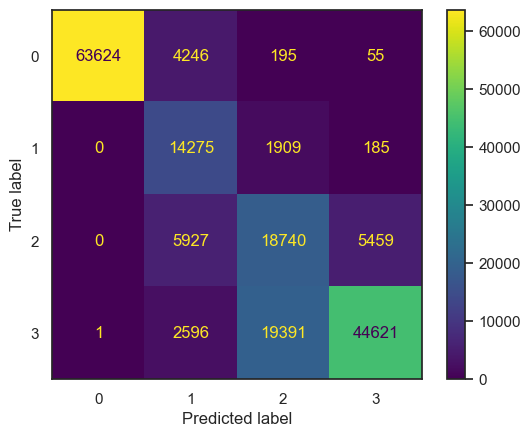

              precision    recall  f1-score   support

           0     1.0000    0.9340    0.9659     68120
           1     0.5278    0.8721    0.6576     16369
           2     0.4658    0.6221    0.5327     30126
           3     0.8867    0.6699    0.7632     66609

    accuracy                         0.7795    181224
   macro avg     0.7201    0.7745    0.7298    181224
weighted avg     0.8269    0.7795    0.7915    181224



In [7]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

# for faster training 
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


# empty list for predicted and actual values
actual_labels_All = []
predicted_labels_fcn_All = []

# empty list for accuracy and variables of each fold which are stored
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []
PR_AVG_Mac = []

ECE = []


tf.keras.backend.clear_session()
initial_lr = 0.001
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=initial_lr)
#optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
# Define the early stopping callback
early_stopping = EarlyStopping(patience=5, monitor="val_loss", mode="min", verbose=1, restore_best_weights=True)
# initialize callbacks 
reduceLR =ReduceLROnPlateau(monitor="val_loss", patience=5, verbose= 1, mode="min", factor= 0.2, min_lr = 1e-5) 

checkpoint = ModelCheckpoint(
    "MHALustomModel.weights.hdf5", monitor="val_loss",
    verbose=1, save_best_only=True, mode="min"
)

callbacks= [early_stopping, checkpoint, reduceLR]


class_counts = np.bincount(Y_abl_train_weights, minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)  # normalize mean≈1
print("Alpha weights:", alpha)

# Define focal loss with tuned alpha and gamma
focloss = tf.keras.losses.CategoricalFocalCrossentropy(
    gamma=1.5,          # focus more on hard examples
    alpha=alpha,        # per-class weights
    )




model_tcn = TCN_model(timesteps = X_abl_train_fold.shape[1], n_features = X_abl_train_fold.shape[2], num_classes = 4 ) 
model_tcn.compile(loss=focloss, optimizer=optimizer, metrics=['categorical_accuracy'])
K.set_value(model_tcn.optimizer.learning_rate, initial_lr)
model_tcn.fit(abl_train_ds, epochs=10, verbose=1)#, validation_data=val_ds, callbacks=callbacks)# class_weight =  class_weights)


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn = model_tcn.predict(X_abl_val_t)
y_pred_tcn = np.argmax(predictions_tcn, axis=1) 
y_true_labels = np.argmax(Y_abl_val_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_tcn)
plt.show()

report_tcn = classification_report(y_true_labels, y_pred_tcn, digits=4)
print(report_tcn)

Physical devices cannot be modified after being initialized

2026-04-29 00:45:02.125005: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 00:45:02.125054: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)



Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]
Epoch 1/10


2026-04-29 00:45:03.593044: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


2463/2463 [==============================] - 233s 93ms/step - loss: 0.2493 - categorical_accuracy: 0.7394
Epoch 2/10
2463/2463 [==============================] - 226s 92ms/step - loss: 0.1891 - categorical_accuracy: 0.7885
Epoch 3/10
2463/2463 [==============================] - 225s 91ms/step - loss: 0.1758 - categorical_accuracy: 0.7994
Epoch 4/10
2463/2463 [==============================] - 226s 92ms/step - loss: 0.1701 - categorical_accuracy: 0.8041
Epoch 5/10
2463/2463 [==============================] - 226s 92ms/step - loss: 0.1649 - categorical_accuracy: 0.8081
Epoch 6/10
2463/2463 [==============================] - 225s 91ms/step - loss: 0.1617 - categorical_accuracy: 0.8108
Epoch 7/10
2463/2463 [==============================] - 225s 92ms/step - loss: 0.1587 - categorical_accuracy: 0.8132
Epoch 8/10
2463/2463 [==============================] - 226s 92ms/step - loss: 0.1560 - categorical_accuracy: 0.8150
Epoch 9/10
2463/2463 [==============================] - 224s 91ms/step - lo

2026-04-29 01:22:44.955785: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


5664/5664 [==============================] - 106s 19ms/step


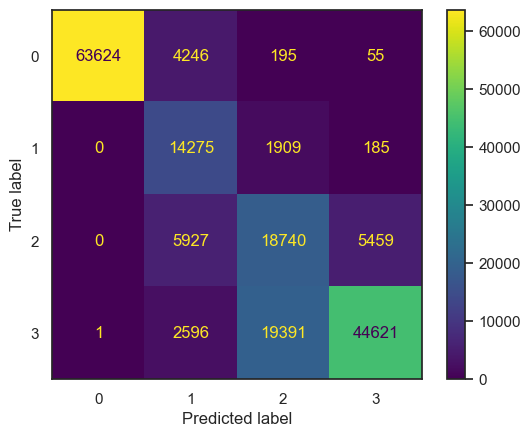

              precision    recall  f1-score   support

           0     1.0000    0.9340    0.9659     68120
           1     0.5278    0.8721    0.6576     16369
           2     0.4658    0.6221    0.5327     30126
           3     0.8867    0.6699    0.7632     66609

    accuracy                         0.7795    181224
   macro avg     0.7201    0.7745    0.7298    181224
weighted avg     0.8269    0.7795    0.7915    181224



In [8]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


# empty list for predicted and actual values
actual_labels_All = []
predicted_labels_fcn_All = []

# empty list for accuracy and variables of each fold which are stored
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []
PR_AVG_Mac = []

ECE = []


tf.keras.backend.clear_session()
initial_lr = 0.001
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=initial_lr)
#optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
# Define the early stopping callback
early_stopping = EarlyStopping(patience=5, monitor="val_loss", mode="min", verbose=1, restore_best_weights=True)
# initialize callbacks 
reduceLR =ReduceLROnPlateau(monitor="val_loss", patience=5, verbose= 1, mode="min", factor= 0.2, min_lr = 1e-5) 

checkpoint = ModelCheckpoint(
    "TCN_nopadModel.weights.hdf5", monitor="val_loss",
    verbose=1, save_best_only=True, mode="min"
)

callbacks= [early_stopping, checkpoint, reduceLR]


class_counts = np.bincount(Y_abl_train_weights, minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)  # normalize mean≈1
print("Alpha weights:", alpha)

# Define focal loss with tuned alpha and gamma
focloss = tf.keras.losses.CategoricalFocalCrossentropy(
    gamma=1.5,          # focus more on hard examples
    alpha=alpha,        # per-class weights
    )




model_tcn = TCN_model(timesteps = X_abl_train_fold.shape[1], n_features = X_abl_train_fold.shape[2], num_classes = 4 , nb_filters=64,
        kernel_size=3,
        dilations=(1, 2, 4, 8, 16),  
        padding="same",
        use_skip_connections=True,
        dropout_rate=0.0, #0.1,
        use_batch_norm=True,
        use_layer_norm=False,
        activation='relu',
        return_sequences=False) 
model_tcn.compile(loss=focloss, optimizer=optimizer, metrics=['categorical_accuracy'])
K.set_value(model_tcn.optimizer.learning_rate, initial_lr)
model_tcn.fit(abl_train_ds, epochs=10, verbose=1)#, validation_data=val_ds, callbacks=callbacks)# class_weight =  class_weights)


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn = model_tcn.predict(X_abl_val_t)
y_pred_tcn = np.argmax(predictions_tcn, axis=1) 
y_true_labels = np.argmax(Y_abl_val_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_tcn)
plt.show()

report_tcn = classification_report(y_true_labels, y_pred_tcn, digits=4)
print(report_tcn)

Physical devices cannot be modified after being initialized

2026-04-29 01:24:33.892523: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 01:24:33.892554: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-04-29 01:24:33.892970: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 01:24:33.892986: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL,


Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]
Epoch 1/10


2026-04-29 01:24:35.431457: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


2463/2463 [==============================] - 172s 69ms/step - loss: 0.2533 - categorical_accuracy: 0.7362
Epoch 2/10
2463/2463 [==============================] - 166s 67ms/step - loss: 0.1893 - categorical_accuracy: 0.7888
Epoch 3/10
2463/2463 [==============================] - 164s 67ms/step - loss: 0.1771 - categorical_accuracy: 0.7989
Epoch 4/10
2463/2463 [==============================] - 163s 66ms/step - loss: 0.1709 - categorical_accuracy: 0.8038
Epoch 5/10
2463/2463 [==============================] - 164s 67ms/step - loss: 0.1657 - categorical_accuracy: 0.8081
Epoch 6/10
2463/2463 [==============================] - 167s 68ms/step - loss: 0.1618 - categorical_accuracy: 0.8108
Epoch 7/10
2463/2463 [==============================] - 164s 67ms/step - loss: 0.1583 - categorical_accuracy: 0.8137
Epoch 8/10
2463/2463 [==============================] - 165s 67ms/step - loss: 0.1556 - categorical_accuracy: 0.8158
Epoch 9/10
2463/2463 [==============================] - 163s 66ms/step - lo

2026-04-29 01:52:14.566393: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


5664/5664 [==============================] - 79s 14ms/step


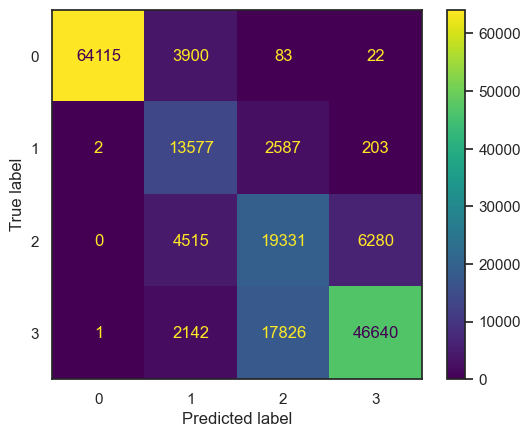

              precision    recall  f1-score   support

           0     1.0000    0.9412    0.9697     68120
           1     0.5626    0.8294    0.6704     16369
           2     0.4854    0.6417    0.5527     30126
           3     0.8776    0.7002    0.7789     66609

    accuracy                         0.7927    181224
   macro avg     0.7314    0.7781    0.7429    181224
weighted avg     0.8299    0.7927    0.8032    181224



In [9]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

tf.compat.v1.set_random_seed(seed_value)
session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

# for faster training 
session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


# empty list for predicted and actual values
actual_labels_All = []
predicted_labels_fcn_All = []

# empty list for accuracy and variables of each fold which are stored
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []
PR_AVG_Mac = []

ECE = []


tf.keras.backend.clear_session()
initial_lr = 0.001
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=initial_lr)
#optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
# Define the early stopping callback
early_stopping = EarlyStopping(patience=5, monitor="val_loss", mode="min", verbose=1, restore_best_weights=True)
# initialize callbacks 
reduceLR =ReduceLROnPlateau(monitor="val_loss", patience=5, verbose= 1, mode="min", factor= 0.2, min_lr = 1e-5) 

checkpoint = ModelCheckpoint(
    "TCN_Norm_Model.weights.hdf5", monitor="val_loss",
    verbose=1, save_best_only=True, mode="min"
)

callbacks= [early_stopping, checkpoint, reduceLR]


class_counts = np.bincount(Y_abl_train_weights, minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)  # normalize mean≈1
print("Alpha weights:", alpha)

# Define focal loss with tuned alpha and gamma
focloss = tf.keras.losses.CategoricalFocalCrossentropy(
    gamma=1.5,          # focus more on hard examples
    alpha=alpha,        # per-class weights
    )




model_tcn = TCN_model(timesteps = X_abl_train_fold.shape[1], n_features = X_abl_train_fold.shape[2], num_classes = 4 , nb_filters=64,
        kernel_size=3,
        dilations=(1, 2, 4, 8),  
        padding="same",
        use_skip_connections=True,
        dropout_rate=0.0, #0.1,
        use_batch_norm=True,
        use_layer_norm=False,
        activation='relu',
        return_sequences=False) 
model_tcn.compile(loss=focloss, optimizer=optimizer, metrics=['categorical_accuracy'])
K.set_value(model_tcn.optimizer.learning_rate, initial_lr)
model_tcn.fit(abl_train_ds, epochs=10, verbose=1)#, validation_data=val_ds, callbacks=callbacks)# class_weight =  class_weights)


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn = model_tcn.predict(X_abl_val_t)
y_pred_tcn = np.argmax(predictions_tcn, axis=1) 
y_true_labels = np.argmax(Y_abl_val_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_tcn)
plt.show()

report_tcn = classification_report(y_true_labels, y_pred_tcn, digits=4)
print(report_tcn)

2026-04-29 01:53:36.126694: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 01:53:36.126736: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-04-29 01:53:36.127337: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 01:53:36.127354: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL,

Physical devices cannot be modified after being initialized
Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]
Epoch 1/10


2026-04-29 01:53:37.461454: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


2463/2463 [==============================] - 224s 89ms/step - loss: 0.2076 - categorical_accuracy: 0.7710
Epoch 2/10
2463/2463 [==============================] - 217s 88ms/step - loss: 0.1728 - categorical_accuracy: 0.8022
Epoch 3/10
2463/2463 [==============================] - 217s 88ms/step - loss: 0.1667 - categorical_accuracy: 0.8077
Epoch 4/10
2463/2463 [==============================] - 217s 88ms/step - loss: 0.1624 - categorical_accuracy: 0.8110
Epoch 5/10
2463/2463 [==============================] - 217s 88ms/step - loss: 0.1602 - categorical_accuracy: 0.8125
Epoch 6/10
2463/2463 [==============================] - 217s 88ms/step - loss: 0.1577 - categorical_accuracy: 0.8144
Epoch 7/10
2463/2463 [==============================] - 218s 88ms/step - loss: 0.1565 - categorical_accuracy: 0.8148
Epoch 8/10
2463/2463 [==============================] - 215s 87ms/step - loss: 0.1551 - categorical_accuracy: 0.8162
Epoch 9/10
2463/2463 [==============================] - 213s 86ms/step - lo

2026-04-29 02:29:42.082208: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


5664/5664 [==============================] - 110s 19ms/step


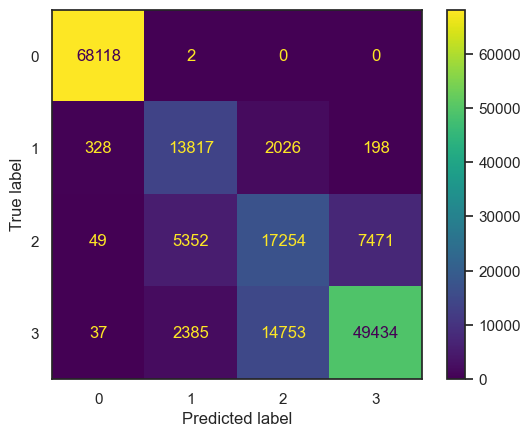

              precision    recall  f1-score   support

           0     0.9940    1.0000    0.9970     68120
           1     0.6410    0.8441    0.7286     16369
           2     0.5070    0.5727    0.5379     30126
           3     0.8657    0.7422    0.7992     66609

    accuracy                         0.8201    181224
   macro avg     0.7519    0.7897    0.7657    181224
weighted avg     0.8340    0.8201    0.8237    181224



In [10]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

tf.compat.v1.set_random_seed(seed_value)
session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

# for faster training 
session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


# empty list for predicted and actual values
actual_labels_All = []
predicted_labels_fcn_All = []

# empty list for accuracy and variables of each fold which are stored
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []
PR_AVG_Mac = []

ECE = []


tf.keras.backend.clear_session()
initial_lr = 0.001
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=initial_lr)
#optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
# Define the early stopping callback
early_stopping = EarlyStopping(patience=5, monitor="val_loss", mode="min", verbose=1, restore_best_weights=True)
# initialize callbacks 
reduceLR =ReduceLROnPlateau(monitor="val_loss", patience=5, verbose= 1, mode="min", factor= 0.2, min_lr = 1e-5) 

checkpoint = ModelCheckpoint(
    "TCN_Norm_Model.weights.hdf5", monitor="val_loss",
    verbose=1, save_best_only=True, mode="min"
)

callbacks= [early_stopping, checkpoint, reduceLR]


class_counts = np.bincount(Y_abl_train_weights, minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)  # normalize mean≈1
print("Alpha weights:", alpha)

# Define focal loss with tuned alpha and gamma
focloss = tf.keras.losses.CategoricalFocalCrossentropy(
    gamma=1.5,          # focus more on hard examples
    alpha=alpha,        # per-class weights
    )




model_tcn = TCN_model(timesteps = X_abl_train_fold.shape[1], n_features = X_abl_train_fold.shape[2], num_classes = 4 , nb_filters=64,
        kernel_size=3,
        dilations=(1, 2, 4, 8, 16),  
        padding="same",
        use_skip_connections=True,
        dropout_rate=0.0, #0.1,
        use_batch_norm=False,
        use_layer_norm=True,
        activation='relu',
        return_sequences=False) 
model_tcn.compile(loss=focloss, optimizer=optimizer, metrics=['categorical_accuracy'])
K.set_value(model_tcn.optimizer.learning_rate, initial_lr)
model_tcn.fit(abl_train_ds, epochs=10, verbose=1)#, validation_data=val_ds, callbacks=callbacks)# class_weight =  class_weights)


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn = model_tcn.predict(X_abl_val_t)
y_pred_tcn = np.argmax(predictions_tcn, axis=1) 
y_true_labels = np.argmax(Y_abl_val_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_tcn)
plt.show()

report_tcn = classification_report(y_true_labels, y_pred_tcn, digits=4)
print(report_tcn)

2026-04-29 02:31:35.013700: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 02:31:35.013723: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-04-29 02:31:35.014364: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 02:31:35.014384: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL,

Physical devices cannot be modified after being initialized
Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]
Epoch 1/10


2026-04-29 02:31:36.371615: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


2463/2463 [==============================] - 369s 149ms/step - loss: 0.2080 - categorical_accuracy: 0.7715
Epoch 2/10
2463/2463 [==============================] - 364s 148ms/step - loss: 0.1725 - categorical_accuracy: 0.8022
Epoch 3/10
2463/2463 [==============================] - 362s 147ms/step - loss: 0.1656 - categorical_accuracy: 0.8083
Epoch 4/10
2463/2463 [==============================] - 367s 149ms/step - loss: 0.1616 - categorical_accuracy: 0.8109
Epoch 5/10
2463/2463 [==============================] - 367s 149ms/step - loss: 0.1591 - categorical_accuracy: 0.8130
Epoch 6/10
2463/2463 [==============================] - 367s 149ms/step - loss: 0.1569 - categorical_accuracy: 0.8144
Epoch 7/10
2463/2463 [==============================] - 368s 149ms/step - loss: 0.1555 - categorical_accuracy: 0.8152
Epoch 8/10
2463/2463 [==============================] - 368s 149ms/step - loss: 0.1539 - categorical_accuracy: 0.8161
Epoch 9/10
2463/2463 [==============================] - 369s 150ms/

2026-04-29 03:32:43.508644: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


5664/5664 [==============================] - 127s 22ms/step


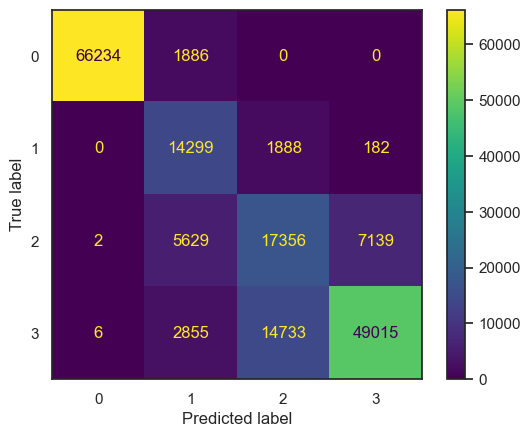

              precision    recall  f1-score   support

           0     0.9999    0.9723    0.9859     68120
           1     0.5796    0.8735    0.6969     16369
           2     0.5108    0.5761    0.5415     30126
           3     0.8700    0.7359    0.7973     66609

    accuracy                         0.8106    181224
   macro avg     0.7401    0.7895    0.7554    181224
weighted avg     0.8329    0.8106    0.8166    181224



In [11]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

tf.compat.v1.set_random_seed(seed_value)
session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

# for faster training 
session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


# empty list for predicted and actual values
actual_labels_All = []
predicted_labels_fcn_All = []

# empty list for accuracy and variables of each fold which are stored
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []
PR_AVG_Mac = []

ECE = []


tf.keras.backend.clear_session()
initial_lr = 0.001
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=initial_lr)
#optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
# Define the early stopping callback
early_stopping = EarlyStopping(patience=5, monitor="val_loss", mode="min", verbose=1, restore_best_weights=True)
# initialize callbacks 
reduceLR =ReduceLROnPlateau(monitor="val_loss", patience=5, verbose= 1, mode="min", factor= 0.2, min_lr = 1e-5) 

checkpoint = ModelCheckpoint(
    "TCN_Norm_Model.weights.hdf5", monitor="val_loss",
    verbose=1, save_best_only=True, mode="min"
)

callbacks= [early_stopping, checkpoint, reduceLR]


class_counts = np.bincount(Y_abl_train_weights, minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)  # normalize mean≈1
print("Alpha weights:", alpha)

# Define focal loss with tuned alpha and gamma
focloss = tf.keras.losses.CategoricalFocalCrossentropy(
    gamma=1.5,          # focus more on hard examples
    alpha=alpha,        # per-class weights
    )




model_tcn = TCN_model(timesteps = X_abl_train_fold.shape[1], n_features = X_abl_train_fold.shape[2], num_classes = 4 , nb_filters=128,
        kernel_size=3,
        dilations=(1, 2, 4, 8, 16),  
        padding="same",
        use_skip_connections=True,
        dropout_rate=0.0, #0.1,
        use_batch_norm=False,
        use_layer_norm=True,
        activation='relu',
        return_sequences=False) 
model_tcn.compile(loss=focloss, optimizer=optimizer, metrics=['categorical_accuracy'])
K.set_value(model_tcn.optimizer.learning_rate, initial_lr)
model_tcn.fit(abl_train_ds, epochs=10, verbose=1) #, validation_data=val_ds, callbacks=callbacks)# class_weight =  class_weights)


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn = model_tcn.predict(X_abl_val_t)
y_pred_tcn = np.argmax(predictions_tcn, axis=1) 
y_true_labels = np.argmax(Y_abl_val_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_tcn)
plt.show()

report_tcn = classification_report(y_true_labels, y_pred_tcn, digits=4)
print(report_tcn)

2026-04-29 03:34:52.997941: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 03:34:52.997971: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-04-29 03:34:52.998581: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 03:34:52.998599: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL,

Physical devices cannot be modified after being initialized
Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]
Epoch 1/10


2026-04-29 03:34:55.220066: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


2463/2463 [==============================] - 412s 165ms/step - loss: 3.0315 - categorical_accuracy: 0.7583
Epoch 2/10
2463/2463 [==============================] - 406s 165ms/step - loss: 3.0101 - categorical_accuracy: 0.7801
Epoch 3/10
2463/2463 [==============================] - 400s 162ms/step - loss: 3.0074 - categorical_accuracy: 0.7828
Epoch 4/10
2463/2463 [==============================] - 405s 164ms/step - loss: 3.0058 - categorical_accuracy: 0.7847
Epoch 5/10
2463/2463 [==============================] - 404s 164ms/step - loss: 1.9372 - categorical_accuracy: 0.7943
Epoch 6/10
2463/2463 [==============================] - 404s 164ms/step - loss: 0.1607 - categorical_accuracy: 0.8115
Epoch 7/10
2463/2463 [==============================] - 402s 163ms/step - loss: 0.1589 - categorical_accuracy: 0.8130
Epoch 8/10
2463/2463 [==============================] - 393s 160ms/step - loss: 0.1560 - categorical_accuracy: 0.8147
Epoch 9/10
2463/2463 [==============================] - 392s 159ms/

2026-04-29 04:41:45.645377: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


5664/5664 [==============================] - 207s 36ms/step


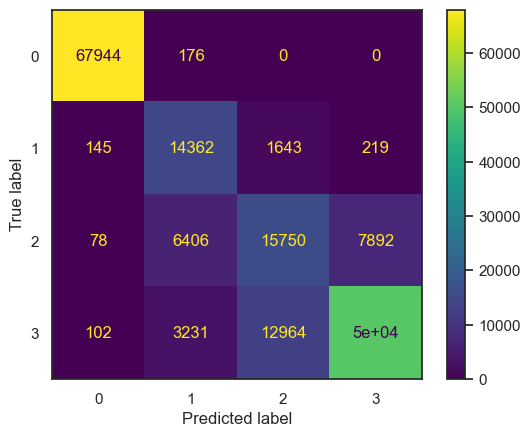

              precision    recall  f1-score   support

           0     0.9952    0.9974    0.9963     68120
           1     0.5941    0.8774    0.7085     16369
           2     0.5188    0.5228    0.5208     30126
           3     0.8612    0.7553    0.8048     66609

    accuracy                         0.8187    181224
   macro avg     0.7423    0.7882    0.7576    181224
weighted avg     0.8305    0.8187    0.8209    181224



In [12]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

tf.compat.v1.set_random_seed(seed_value)
session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

# for faster training 
session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


# empty list for predicted and actual values
actual_labels_All = []
predicted_labels_fcn_All = []

# empty list for accuracy and variables of each fold which are stored
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []
PR_AVG_Mac = []

ECE = []


tf.keras.backend.clear_session()
initial_lr = 0.001
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=initial_lr)
#optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
# Define the early stopping callback
early_stopping = EarlyStopping(patience=5, monitor="val_loss", mode="min", verbose=1, restore_best_weights=True)
# initialize callbacks 
reduceLR =ReduceLROnPlateau(monitor="val_loss", patience=5, verbose= 1, mode="min", factor= 0.2, min_lr = 1e-5) 

checkpoint = ModelCheckpoint(
    "TCN_Norm_Model.weights.hdf5", monitor="val_loss",
    verbose=1, save_best_only=True, mode="min"
)

callbacks= [early_stopping, checkpoint, reduceLR]


class_counts = np.bincount(Y_abl_train_weights, minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)  # normalize mean≈1
print("Alpha weights:", alpha)

# Define focal loss with tuned alpha and gamma
focloss = tf.keras.losses.CategoricalFocalCrossentropy(
    gamma=1.5,          # focus more on hard examples
    alpha=alpha,        # per-class weights
    )




model_tcn = TCN_model(timesteps = X_abl_train_fold.shape[1], n_features = X_abl_train_fold.shape[2], num_classes = 4 , nb_filters=64,
        kernel_size=3,
         nb_stacks=2,
        dilations=(1, 2, 4, 8, 16),  
        padding="same",
        use_skip_connections=True,
        dropout_rate=0.0, #0.1,
        use_batch_norm=False,
        use_layer_norm=True,
        activation='relu',
        return_sequences=False) 
model_tcn.compile(loss=focloss, optimizer=optimizer, metrics=['categorical_accuracy'])
K.set_value(model_tcn.optimizer.learning_rate, initial_lr)
model_tcn.fit(abl_train_ds, epochs=10, verbose=1)#, validation_data=val_ds, callbacks=callbacks)# class_weight =  class_weights)


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn = model_tcn.predict(X_abl_val_t)
y_pred_tcn = np.argmax(predictions_tcn, axis=1) 
y_true_labels = np.argmax(Y_abl_val_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_tcn)
plt.show()

report_tcn = classification_report(y_true_labels, y_pred_tcn, digits=4)
print(report_tcn)

In [72]:
pip freeze

absl-py==1.4.0
adbc-driver-manager==1.6.0
adbc-driver-sqlite==1.6.0
alembic==1.16.2
altair==5.5.0
annotated-types==0.7.0
anyio==3.7.1
appnope==0.1.3
argon2-cffi==21.3.0
argon2-cffi-bindings==21.2.0
arrow==1.2.3
asttokens==2.2.1
astunparse==1.6.3
async-lru==2.0.4
attrs==23.1.0
babel==2.17.0
backcall==0.2.0
beautifulsoup4==4.12.2
bibtexparser==1.4.3
biopython==1.85
bleach==6.0.0
cachetools==5.5.2
certifi==2023.7.22
cffi==1.15.1
charset-normalizer==3.2.0
click==8.1.8
cloudpickle==3.1.1
colorlog==6.9.0
comm==0.1.3
commonmark==0.9.1
connectorx==0.4.3
contourpy==1.1.0
cycler==0.11.0
dask==2025.4.0
debugpy==1.6.7
decorator==5.1.1
defusedxml==0.7.1
deltalake==0.25.5
docutils==0.22.2
et_xmlfile==2.0.0
executing==1.2.0
faicons==0.2.2
fastexcel==0.14.0
fastjsonschema==2.18.0
filelock==3.19.1
flatbuffers==23.5.26
fonttools==4.41.1
fqdn==1.5.1
fsspec==2025.3.2
gast==0.4.0
gevent==25.5.1
google-auth==2.22.0
google-auth-oauthlib==1.0.0
google-pasta==0.2.0
great-tables==0.17.0
greenlet==3.2.2
grpcio==

2026-04-29 21:55:46.823608: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 21:55:46.823638: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-04-29 21:55:46.825572: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 21:55:46.825590: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL,

Physical devices cannot be modified after being initialized
Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]
Epoch 1/10


2026-04-29 21:55:49.186066: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


2463/2463 [==============================] - 156s 62ms/step - loss: 0.1972 - categorical_accuracy: 0.7791
Epoch 2/10
2463/2463 [==============================] - 148s 60ms/step - loss: 0.1718 - categorical_accuracy: 0.8031
Epoch 3/10
2463/2463 [==============================] - 149s 61ms/step - loss: 0.1658 - categorical_accuracy: 0.8088
Epoch 4/10
2463/2463 [==============================] - 153s 62ms/step - loss: 0.1620 - categorical_accuracy: 0.8119
Epoch 5/10
2463/2463 [==============================] - 152s 62ms/step - loss: 0.1596 - categorical_accuracy: 0.8134
Epoch 6/10
2463/2463 [==============================] - 144s 59ms/step - loss: 0.1580 - categorical_accuracy: 0.8143
Epoch 7/10
2463/2463 [==============================] - 151s 61ms/step - loss: 0.1558 - categorical_accuracy: 0.8155
Epoch 8/10
2463/2463 [==============================] - 151s 61ms/step - loss: 0.1542 - categorical_accuracy: 0.8165
Epoch 9/10
2463/2463 [==============================] - 152s 62ms/step - lo

2026-04-29 22:20:55.805691: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


5664/5664 [==============================] - 87s 15ms/step


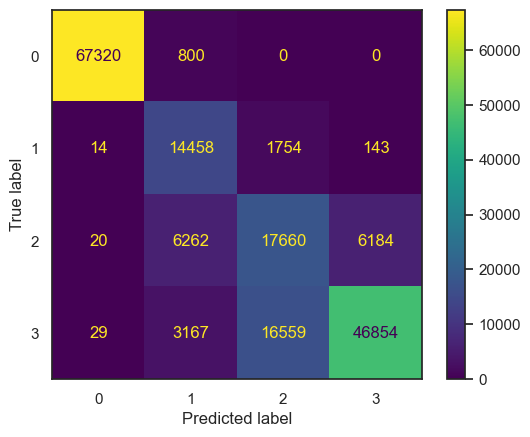

              precision    recall  f1-score   support

           0     0.9991    0.9883    0.9936     68120
           1     0.5857    0.8833    0.7043     16369
           2     0.4909    0.5862    0.5343     30126
           3     0.8810    0.7034    0.7823     66609

    accuracy                         0.8072    181224
   macro avg     0.7392    0.7903    0.7536    181224
weighted avg     0.8339    0.8072    0.8135    181224



In [21]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

tf.compat.v1.set_random_seed(seed_value)
session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

# for faster training 
session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


# empty list for predicted and actual values
actual_labels_All = []
predicted_labels_fcn_All = []

# empty list for accuracy and variables of each fold which are stored
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []
PR_AVG_Mac = []

ECE = []


tf.keras.backend.clear_session()
initial_lr = 0.001
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=initial_lr)
#optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
# Define the early stopping callback
early_stopping = EarlyStopping(patience=5, monitor="val_loss", mode="min", verbose=1, restore_best_weights=True)
# initialize callbacks 
reduceLR =ReduceLROnPlateau(monitor="val_loss", patience=5, verbose= 1, mode="min", factor= 0.2, min_lr = 1e-5) 

checkpoint = ModelCheckpoint(
    "TCN_Norm_Model.weights.hdf5", monitor="val_loss",
    verbose=1, save_best_only=True, mode="min"
)

callbacks= [early_stopping, checkpoint, reduceLR]


class_counts = np.bincount(Y_abl_train_weights, minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)  # normalize mean≈1
print("Alpha weights:", alpha)

# Define focal loss with tuned alpha and gamma
focloss = tf.keras.losses.CategoricalFocalCrossentropy(
    gamma=1.5,          # focus more on hard examples
    alpha=alpha,        # per-class weights
    )




model_tcn = TCN_model(timesteps = X_abl_train_fold.shape[1], n_features = X_abl_train_fold.shape[2], num_classes = 4 , nb_filters=64,
        kernel_size=3,
        dilations=(1, 2, 4, 8),  
        padding="same",
        use_skip_connections=True,
        dropout_rate=0.0, #0.1,
        use_batch_norm=False,
        use_layer_norm=True,
        activation='relu',
        return_sequences=False) 
model_tcn.compile(loss=focloss, optimizer=optimizer, metrics=['categorical_accuracy'])
K.set_value(model_tcn.optimizer.learning_rate, initial_lr)
model_tcn.fit(abl_train_ds, epochs=10, verbose=1)#, validation_data=val_ds, callbacks=callbacks)# class_weight =  class_weights)


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn = model_tcn.predict(X_abl_val_t)
y_pred_tcn = np.argmax(predictions_tcn, axis=1) 
y_true_labels = np.argmax(Y_abl_val_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_tcn)
plt.show()

report_tcn = classification_report(y_true_labels, y_pred_tcn, digits=4)
print(report_tcn)